# Yen carry trade unwind (August 2024)

This notebook reproduces the whole project from scratch: data download, cleaning,
modelling table, hypothesis tests (H1–H5) and robustness checks.

**How to run:** select the project's `.venv` kernel (see *Installation* in the README),
then *Run All*. Every step calls the code in `src/`; outputs are saved to
`data/`, `data_des/` and `results/` and shown below.

| Step | Module | Output |
|---|---|---|
| 1. Download | `src/data/*.py` | `data/*.parquet` |
| 2. Daily merge | `src/cleaning.py` | `data/merged_daily.parquet` |
| 3. Weekly table | `src/modelling_table.py` | `data/modelling_table.parquet` |
| 4. Data description | `src/data_description.py` | `data_des/` |
| 5. H1 skewness / kurtosis | `src/skewness_kurtosis.py` | printed |
| 6. H2–H4 quantile regressions | `src/quantile_regressions.py` | `results/quantile_coefs.*` |
| 7. H5 walk-forward | `src/walk_forward.py` | `results/walk_forward_*` |
| 8. Robustness | `src/robustness/*.py` | `results/robustness_*.csv` |
| 9. Tests | `tests/` | pytest report |

Design choices are documented in `docs/decisions.md`.

## 0. Setup

In [1]:
import runpy
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Make `src` importable even without `pip install -e .`
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "Open this notebook from the repository root"
sys.path.insert(0, str(ROOT))

from src import config

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 140)

# Set to True to re-download every source even if its file already exists
FORCE_DOWNLOAD = False

print("Analysis window:", config.START, "to", config.END)

Analysis window: 2000-01-01 to 2026-09-30


## 1. Download the data

Sources: Yahoo Finance (FX, equities, VIX, Bitcoin, commodities), FRED (US/Japan
3-month rates), CFTC (yen futures positioning), BIS (yen credit outside Japan),
MoF Japan (FX interventions). Each module checks its file and adds a
`release_date` column so that later steps only use data that was public at the time.

A source is downloaded only if its file is missing (or `FORCE_DOWNLOAD = True`).
The CFTC download takes a few minutes.

In [2]:
from src.data import bis, cftc, fred, mof, yahoo

downloads = {
    "yahoo": (yahoo.OUTPUT_FILE, lambda: yahoo.save_prices(yahoo.download_prices())),
    "fred":  (fred.OUTPUT_FILE,  lambda: fred.save_fred(fred.fetch_fred())),
    "cftc":  (cftc.OUTPUT_FILE,  lambda: cftc.save_cftc(cftc.fetch_cftc())),
    "bis":   (bis.OUTPUT_FILE,   lambda: bis.save_credit(bis.download_credit())),
    "mof":   (mof.OUTPUT_FILE,   lambda: mof.fetch_mof()),  # fetch_mof saves the file itself
}

for name, (path, download) in downloads.items():
    if FORCE_DOWNLOAD or not path.exists():
        print(f"Downloading {name}...")
        download()
    print(f"{name:6s} {len(pd.read_parquet(path)):6d} rows  ->  {path.relative_to(ROOT)}")

yahoo    8234 rows  ->  data/yahoo_prices.parquet
fred      321 rows  ->  data/fred_rates.parquet
cftc     1396 rows  ->  data/cftc_jpy.parquet
bis       106 rows  ->  data/bis_credit.parquet
mof       169 rows  ->  data/mof_interventions.parquet


## 2. Daily merge

One row per USD/JPY trading day. Columns ending in `_known` only use a value from the
trading day after its release date (no look-ahead).

In [3]:
from src import cleaning

daily = cleaning.build_daily(cleaning.load_sources())
cleaning.save_daily(daily)
print(f"{len(daily)} rows x {daily.shape[1]} columns")
daily.tail()

6940 rows x 20 columns


,usdjpy,nikkei,nasdaq,sp500,bitcoin,usdmxn,gold,brent,vix,us_3m,jp_3m,rate_diff,us_3m_known,jp_3m_known,rate_diff_known,spec_net_known,spec_net_pct_oi_known,open_interest_known,credit_known,intervention_bn_jpy
date,,,,,,,,,,,,,,,,,,,,
2026-09-24,158.2650,65513.9883,26939.3691,7704.1299,84379.0625,17.5413,4298.0000,106.6000,15.6700,3.9400,NaN,NaN,3.7700,1.4120,2.3580,120359.0000,0.2217,542802.0000,68.3127,0.0000
2026-09-25,158.8110,66364.2031,27068.7207,7743.4102,84034.9219,17.7387,4321.2002,104.3200,14.8700,3.9400,NaN,NaN,3.7700,1.4120,2.3580,120359.0000,0.2217,542802.0000,68.3127,0.0000
2026-09-28,157.4630,65877.6172,26820.3809,7683.6899,83502.6094,17.7487,4168.3999,105.2800,16.0700,3.9400,NaN,NaN,3.7700,1.4120,2.3580,71982.0000,0.1901,378701.0000,68.3127,0.0000
2026-09-29,157.3610,65481.2695,26797.5391,7670.8398,83622.4297,17.9720,4179.7002,102.5900,16.0400,3.9400,NaN,NaN,3.7700,1.4120,2.3580,71982.0000,0.1901,378701.0000,68.3127,0.0000
2026-09-30,157.4040,66753.7188,26861.0605,7651.5400,83553.8516,18.0436,4186.7002,103.5300,16.3400,3.9400,NaN,NaN,3.7700,1.4120,2.3580,71982.0000,0.1901,378701.0000,68.3127,0.0000


## 3. Weekly modelling table

Friday closes; targets are the 1-week and 4-week forward carry returns of a long USD / short JPY position
(spot move + rate differential); features use only data public on that Friday.

In [4]:
from src import modelling_table

table = modelling_table.build_modelling_table()
table.to_parquet(config.DIRECTORY / "modelling_table.parquet", index=True)
print(f"{len(table)} weeks, {table.index[0].date()} to {table.index[-1].date()}")
table.describe().T

1393 weeks, 2000-01-07 to 2026-09-25


,count,mean,std,min,25%,50%,75%,max
usdjpy,1393.0000,113.6550,19.3554,75.9300,104.1090,110.9210,120.5500,163.8320
rv_20d,1389.0000,0.0908,0.0365,0.0220,0.0654,0.0842,0.1112,0.3159
vix,1393.0000,19.5981,8.2559,9.1400,13.9100,17.4500,22.9600,79.1300
us_rate,1389.0000,2.1898,1.9897,0.0900,0.2400,1.6500,3.9400,6.5900
jp_rate,1272.0000,0.2641,0.3180,-0.0720,0.0560,0.1255,0.3500,1.5599
rate_diff,1268.0000,1.6946,1.7834,-0.3200,-0.0032,1.1700,2.8500,5.4720
us_3m_known,1380.0000,2.1728,1.9902,0.0900,0.2400,1.6100,3.9600,6.5900
jp_3m_known,1263.0000,0.2550,0.3013,-0.0720,0.0560,0.1100,0.3400,1.4120
rate_diff_known,1263.0000,1.6900,1.7864,-0.3200,-0.0130,1.1700,2.8500,5.4720
carry_to_vol,1263.0000,0.2151,0.2542,-0.0363,-0.0017,0.1328,0.3625,1.3596


## 4. Data description

,mean,skew,excess_kurtosis
fwd_carry_4w,0.0019,-0.0730,0.6753
fwd_carry_1w,0.0005,-0.1770,1.6101


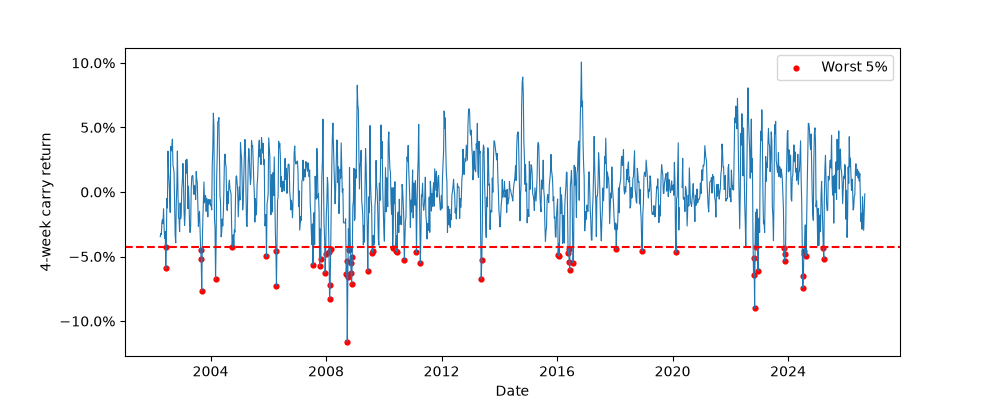

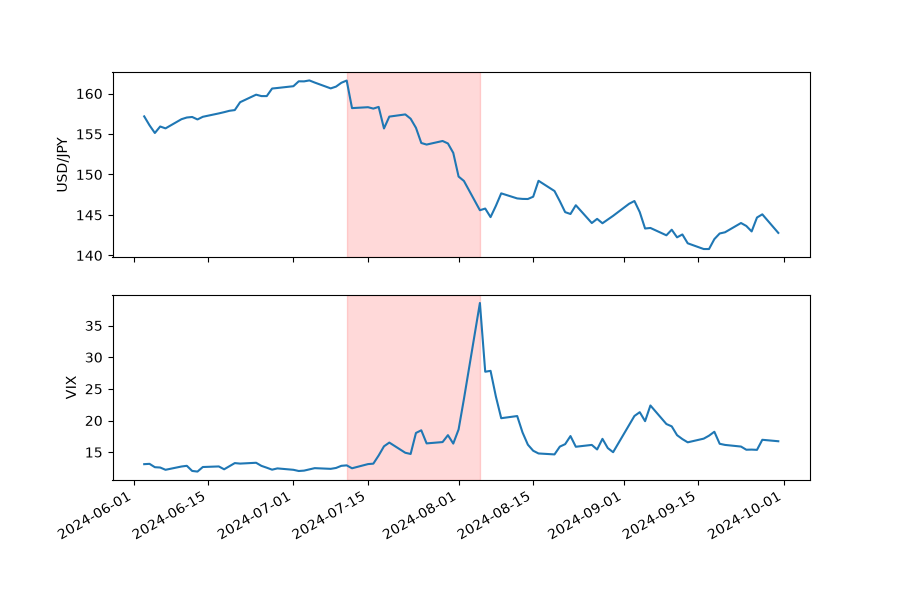

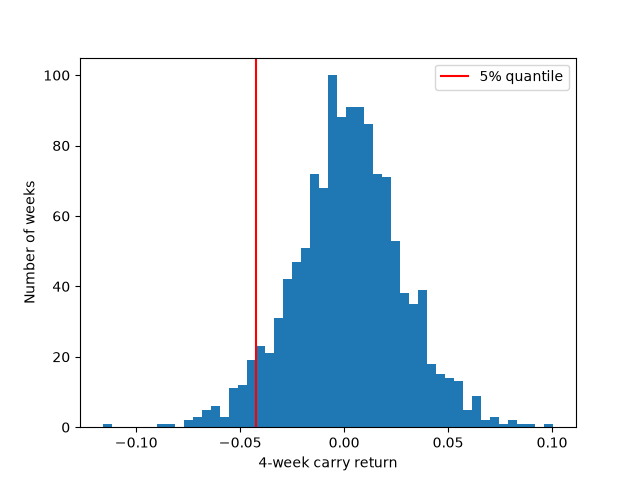

In [5]:
runpy.run_module("src.data_description", run_name="__main__")

display(pd.read_csv(ROOT / "data_des" / "target_stats.csv", index_col=0))
for name in ["unwind_in_history", "2024_unwind", "hist_carry_4w"]:
    display(Image(ROOT / "data_des" / f"{name}.png"))

## 5. H1: Negative skewness and fat left tails

Skewness and excess kurtosis of carry returns. The 1-week tests assume independent
weeks; the 4-week returns overlap, so their intervals come from a 12-week block bootstrap.

In [6]:
from src import skewness_kurtosis

skewness_kurtosis.run()

1-week carry (n=1268):
  skewness: -0.1770; skewtest: SkewtestResult(statistic=np.float64(-2.5662624461312977), pvalue=np.float64(0.010280101391147194))
  excess kurtosis: 1.6101
  kurtosis test: KurtosistestResult(statistic=np.float64(6.9243218024527255), pvalue=np.float64(4.380690785834478e-12))
  Jarque-Bera test: SignificanceResult(statistic=np.float64(141.6979464573562), pvalue=np.float64(1.7009121298404858e-31))
4-week carry (n=1268; 12-week block bootstrap):
  skewness: -0.0730; 95% CI=[-0.3590, 0.1723]
  excess kurtosis: 0.6753; 95% CI=[0.1610, 1.2408]


## 6. H2–H4: In-sample quantile regressions

4-week carry return on `spec_net_z` (H2, CFTC positioning), `carry_to_vol` (H3),
`credit_yoy` (H4, BIS yen credit) and `vix` (control), at the 5%, 50% and 95% quantiles and OLS.
Features scaled to mean 0 and std 1; 95% intervals from a 12-week block bootstrap
(500 draws, takes about a minute).

model,OLS,q0.05,q0.50,q0.95
variable,,,,
Intercept,0.0022,-0.0421,0.0024,0.0456
carry_to_vol,-0.0006,-0.0021,0.0016,-0.0059
credit_yoy,0.0006,-0.0024,0.0009,0.0042
spec_net_z,-0.0009,-0.0018,-0.0012,-0.0009
vix,-0.0021,-0.0040,-0.0017,0.0021


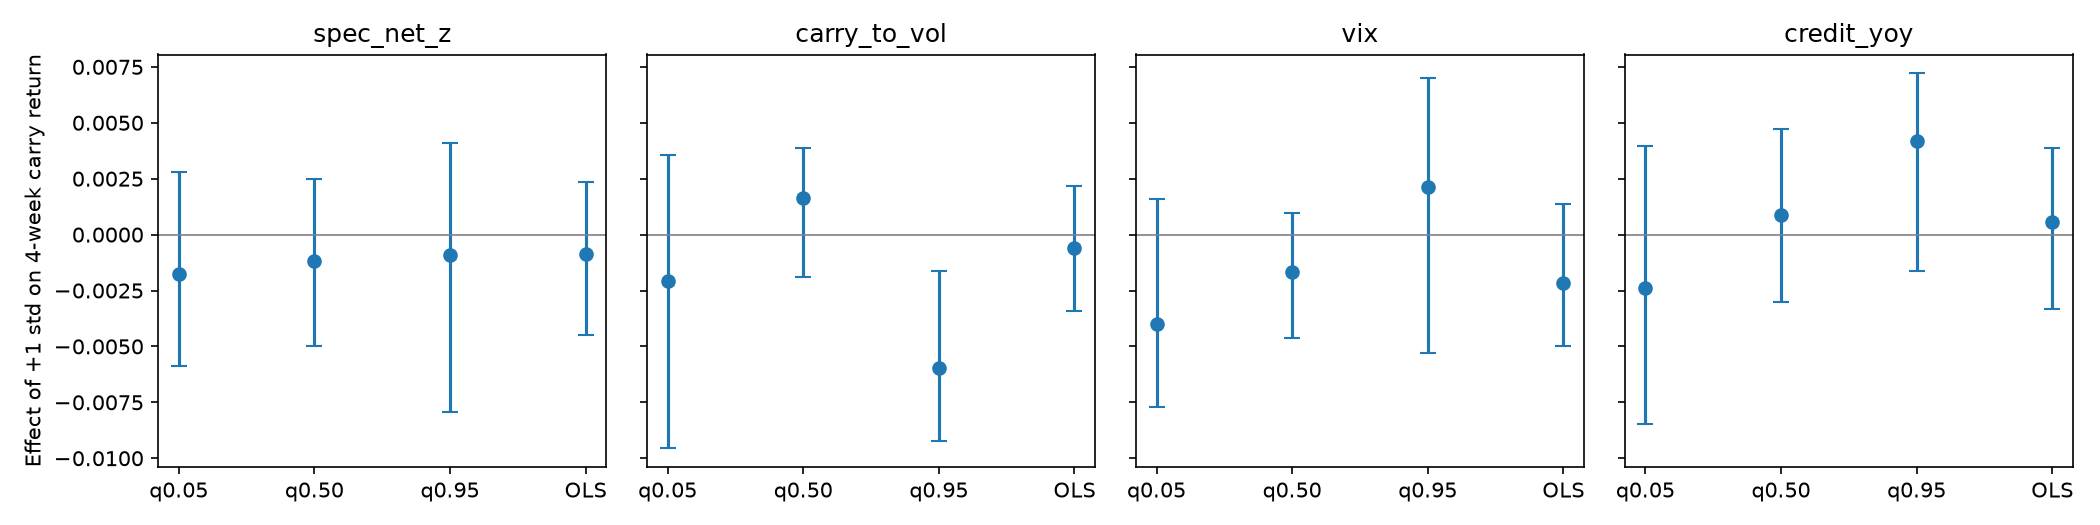

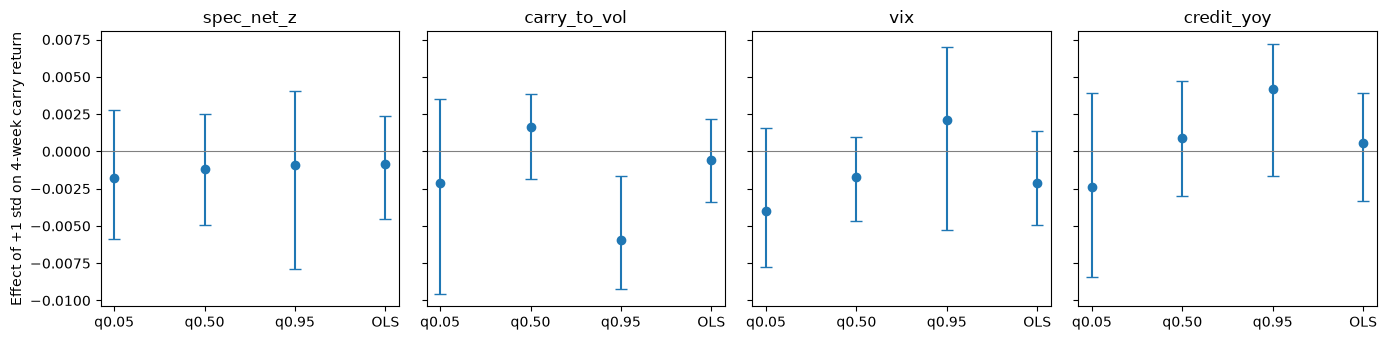

In [11]:
from src import quantile_regressions

coefs = quantile_regressions.run()
display(coefs.pivot(index="variable", columns="model", values="coef"))
display(Image(quantile_regressions.RESULTS / "quantile_coefs.png"))

## 7. H5: Walk-forward validation of the 5% quantile

Each week from July 2012 the model is refit on data known at that date only
(expanding window, 4-week embargo, features scaled on the training window) and its
5% quantile forecast is compared with the historical quantile and a volatility-scaled normal.

Scores: coverage (target 5%), Kupiec p-value, pinball loss (lower is better) and skill
versus the historical quantile (> 0 means better), with and without 2024.

coverage  kupiec_p  pinball  skill_vs_hist
all          model     0.0395    0.1739   0.0028        -0.0073
             hist      0.0381    0.1228   0.0028         0.0000
             normal    0.0612    0.1767   0.0029        -0.0208
without_2024 model     0.0366    0.0923   0.0027         0.0048
             hist      0.0337    0.0379   0.0027         0.0000
             normal    0.0615    0.1827   0.0028        -0.0109

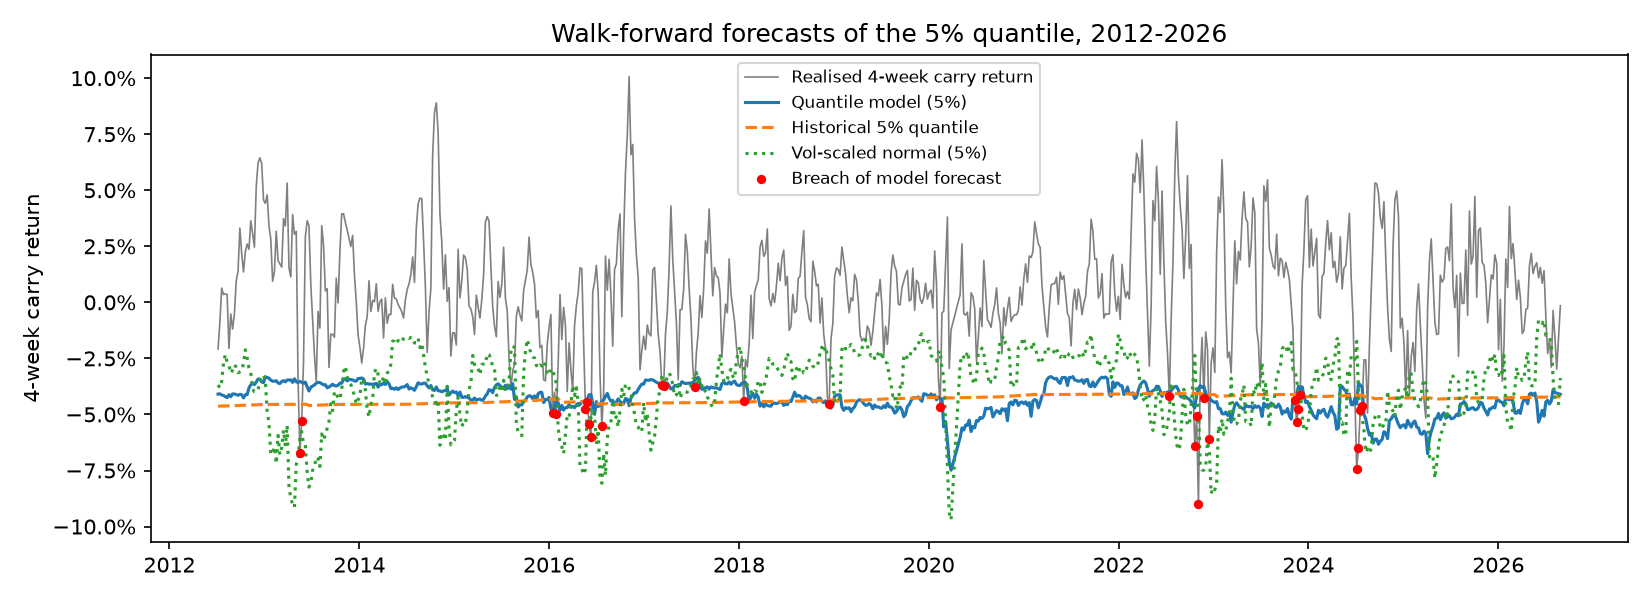

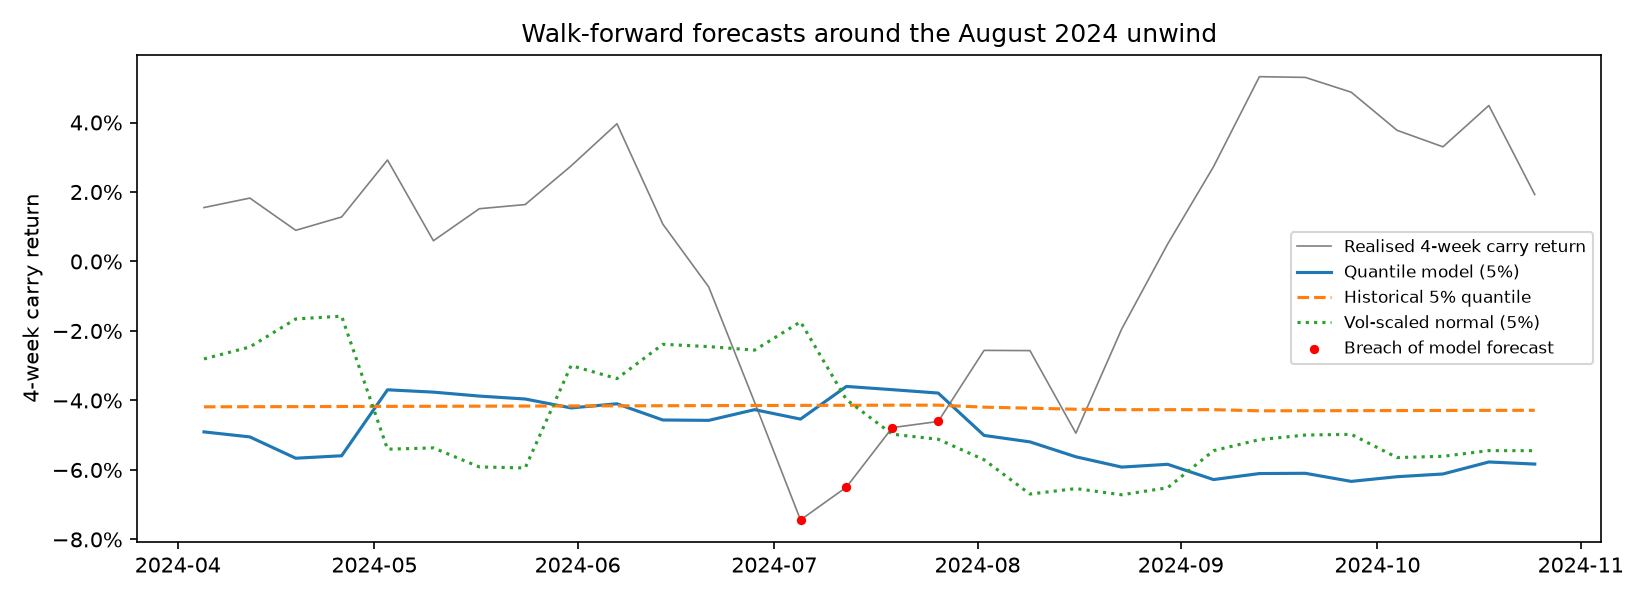

In [8]:
from src import walk_forward

scores = walk_forward.run()
display(scores)
display(Image(walk_forward.RESULTS / "walk_forward.png"))
display(Image(walk_forward.RESULTS / "walk_forward_2024.png"))

## 8. Robustness checks

Each variation changes one choice at a time (1-week target, 10% quantile, later start,
without 2024, without the 2025 rate break, without intervention weeks, 6-month BIS lag).

In [10]:
from src.robustness import robustness_qr, robustness_wf

print("Quantile regressions:")
display(robustness_qr.run())
print("Walk-forward:")
display(robustness_wf.run())

Quantile regressions:


/Users/deric/Documents/Group-Exo/Group-Exo/src/quantile_regressions.py:40: IterationLimitWarning: Maximum number of iterations (1000) reached.
  return smf.quantreg(formula, data).fit(q=q).params


,variation,feature,coef,ci_low,ci_high,same_sign_as_baseline,excludes_zero
0,baseline,spec_net_z,-0.0018,-0.0059,0.0028,True,False
1,baseline,carry_to_vol,-0.0021,-0.0096,0.0035,True,False
2,baseline,vix,-0.0040,-0.0077,0.0016,True,False
3,baseline,credit_yoy,-0.0024,-0.0084,0.0039,True,False
4,1-week target,spec_net_z,-0.0012,-0.0028,0.0014,True,False
5,1-week target,carry_to_vol,-0.0012,-0.0043,0.0017,True,False
6,1-week target,vix,-0.0052,-0.0078,-0.0015,True,True
7,1-week target,credit_yoy,-0.0011,-0.0039,0.0027,True,False
8,10% tail,spec_net_z,-0.0014,-0.0054,0.0038,True,False
9,10% tail,carry_to_vol,-0.0021,-0.0075,0.0035,True,False


Walk-forward:


,variation,n_test_weeks,model_pinball,hist_pinball,normal_pinball,skill_vs_hist,model_coverage,kupiec_p,model_beats_both
0,baseline,735,0.0028,0.0028,0.0029,-0.0073,0.0395,0.1739,False
1,without 2024 (scoring),683,0.0027,0.0027,0.0028,0.0048,0.0366,0.0923,True
2,1-week target,735,0.0014,0.0015,0.0015,0.0212,0.0367,0.0839,True
3,10% tail,735,0.0047,0.0047,0.0047,-0.0072,0.0871,0.2334,False
4,before 2025 rate break,648,0.0029,0.0029,0.0029,0.0004,0.0448,0.5330,True
5,6-month BIS lag,727,0.0028,0.0028,0.0029,0.0013,0.0413,0.2658,True
6,without interventions (scoring),708,0.0028,0.0028,0.0028,-0.0105,0.0381,0.1313,False


## 9. Tests

Checks on the downloaded files, the merge, the modelling table and the walk-forward
(including the no-look-ahead test).

In [ ]:
import pytest

pytest.main(["-q", str(ROOT / "tests")])